# Neutrinos in qg terms (§151, §152, §154, §156)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Viny2030/qang/blob/main/notebooks/qang_neutrinos.ipynb)

A neutrino is produced and detected in a flavour state (e, μ, τ) but travels as a superposition of mass states, so flavour oscillation is a rotation of a two- or three-level system: exactly what qang's qg read-out describes. This notebook runs the four neutrino studies of RESEARCH_NOTES on **local simulators of IBM devices** (`Fake*` backends with calibrated noise; no account, no hardware), always comparing the read-out **without qang** (raw shots) and **with qang** (the qg filter: keep the shots in the conserved Hamming-weight sector, plus readout correction).

| § | topic | published finding |
|---|---|---|
| 151 | vacuum oscillations; three flavours on three qubits | qg_Z = cos²2θ + sin²2θ cos Δ; at the maximum the mixing angle is a quarter of the qang angle; filter 3.4× |
| 152 | through the Earth: matter (MSW) | matter fakes CP violation (A_CP = 0.042 at δ_CP = 0); filter 2.8× |
| 154 | collective oscillations in a dense neutrino gas | what is conserved is the number of ν₂ (mass basis), not the flavour number; filter 2.2–2.8× there |
| 156 | solar neutrinos: the adiabatic MSW conversion | P_ee falls from 0.54 to 0.30; the whole Sun is one rotation |

What the link is, and is not: it is modelling. The oscillation is a rotation and qang reads it with known error bars; it does not remove the trigonometry in general and it is not a speed-up. Published runs used 3 backends and more shots; here 2 backends and fewer shots (about 5 minutes in total on a laptop CPU).

## 1. Install

In [1]:
import importlib, subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "qang", "qiskit-aer", "qiskit-ibm-runtime", "matplotlib"], check=False)
importlib.invalidate_caches()
try:
    from qang import neutrino
    ok = all(hasattr(neutrino, f) for f in ("collective_trotter_circuit", "solar_circuit"))
except ImportError:
    ok = False
if not ok:  # the published qang predates §154/§156: install from GitHub
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--force-reinstall", "--no-deps",
                    "git+https://github.com/Viny2030/qang.git"], check=True)
    print("installed qang from GitHub; if an import fails below, restart the runtime once")
import qang
print("qang", qang.__version__)

qang 0.10.0


## 2. Shared set-up

In [2]:
import math, time
import numpy as np
import matplotlib.pyplot as plt
import qiskit_ibm_runtime.fake_provider as fp
from qiskit import transpile
from qiskit.quantum_info import Statevector
from qang import ibm
from qang import neutrino as nu

BACKENDS = ("FakeBrisbane", "FakeTorino")   # ECR and CZ native gates
FR = "filtered_readout"
T0 = time.time()


def sampler(backend):
    try:
        from qiskit_ibm_runtime.executor_sampler import Sampler
    except ImportError:
        from qiskit_ibm_runtime import SamplerV2 as Sampler
    return Sampler(mode=backend)


def run(circuits, b, weight, shots):
    ts = [transpile(qc, b, optimization_level=1, seed_transpiler=137) for qc in circuits]
    res = sampler(b).run(ts, shots=shots).result()
    return [ibm.ibm_qg(r, t, b, weight=weight) for r, t in zip(res, ts)]

## 3. Vacuum oscillations (§151)

**Two flavours on one qubit.** Going to the mass basis, letting the mass states pick up the phase Δ = Δm² L / 2E and coming back gives

qg_Z = 1 − 2 P(e→μ) = cos²(2θ) + sin²(2θ) cos Δ,

the spherical law of cosines: the Bloch vector precesses on a cone of half-angle 2θ and the qang angle arccos(qg_Z) is the distance travelled. At the oscillation maximum (Δ = π) it equals 4θ exactly, so θ = arccos(qg_Z)/4 inherits the θ-independent shot noise 1/(4√(N + 1/2)) of §125. Elsewhere the relation is not linear: qg removes the sin² only at the maximum.

In [3]:
rng = np.random.default_rng(151)
N_SHOTS = 1000
print(f"theta   mean of theta_hat   std   (theory {nu.mixing_angle_std(N_SHOTS):.4f})")
for th in (0.1, 0.3, 0.5, 0.7):
    k = rng.binomial(N_SHOTS, nu.two_flavour_probability(th, math.pi), 2000)
    est = np.array([nu.mixing_angle_from_maximum(1 - 2 * x / N_SHOTS) for x in k])
    print(f"{th:4.1f}    {est.mean():.4f}              {est.std(ddof=1):.4f}")

theta   mean of theta_hat   std   (theory 0.0079)
 0.1    0.0999              0.0079
 0.3    0.2999              0.0077
 0.5    0.5000              0.0078
 0.7    0.7006              0.0080


**Three flavours on three qubits**, one excitation: qubit k excited = flavour k (e, μ, τ). The PMNS matrix is three RBS rotations and two phase gates, propagation one phase gate per qubit, so every gate conserves the weight and the filter applies. A ν_μ beam over 1300 km (a DUNE-like baseline), δ_CP = −π/2. Published: mean |P̂ − P| raw / filter + readout 0.048 / 0.013 (Brisbane), 0.034 / 0.010 (Torino); the CP asymmetry A_CP = P(ν_μ→ν_e) − P(ν̄_μ→ν̄_e) at 2.6 GeV (exact 0.025) survives even without the filter, because it is a difference of two nearly identical circuits.

exact P(mu -> e, mu, tau) at 2.6 GeV: [0.063 0.013 0.924]
exact A_CP at 2.6 GeV: 0.0250


FakeBrisbane: mean |P_hat - P| raw 0.053, filtered+readout 0.018 (gain 3.0x); A_CP raw 0.0225, filtered+readout 0.0238


FakeTorino: mean |P_hat - P| raw 0.033, filtered+readout 0.010 (gain 3.1x); A_CP raw 0.0276, filtered+readout 0.0286


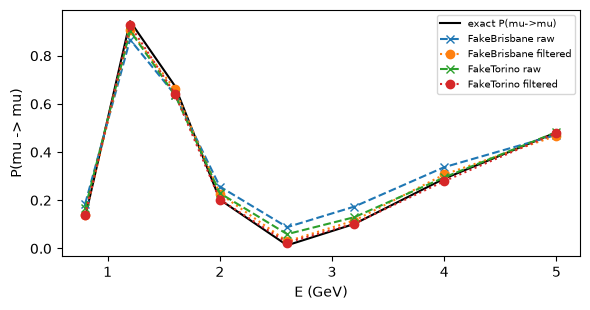

In [4]:
L, DCP = 1300.0, -math.pi / 2
ENERGIES = (0.8, 1.2, 1.6, 2.0, 2.6, 3.2, 4.0, 5.0)
exact = np.array([nu.three_flavour_probabilities(L, E, DCP)[1] for E in ENERGIES])
print("exact P(mu -> e, mu, tau) at 2.6 GeV:", np.round(nu.three_flavour_probabilities(L, 2.6, DCP)[1], 3))
print(f"exact A_CP at 2.6 GeV: {nu.cp_asymmetry(L, 2.6, DCP):.4f}")
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(ENERGIES, exact[:, 1], "k-", label="exact P(mu->mu)")
for name in BACKENDS:
    b = getattr(fp, name)()
    outs = run([nu.three_flavour_circuit("mu", L, E, DCP) for E in ENERGIES], b, 1, 2000)
    err = {k: np.abs(np.array([ibm.occupations(o, k) for o in outs]) - exact).mean() for k in ("raw", FR)}
    oc = run([nu.three_flavour_circuit("mu", L, 2.6, DCP, anti) for anti in (False, True)], b, 1, 10000)
    acp = {k: ibm.occupations(oc[0], k)[0] - ibm.occupations(oc[1], k)[0] for k in ("raw", FR)}
    print(f"{name}: mean |P_hat - P| raw {err['raw']:.3f}, filtered+readout {err[FR]:.3f} "
          f"(gain {err['raw'] / err[FR]:.1f}x); A_CP raw {acp['raw']:.4f}, filtered+readout {acp[FR]:.4f}")
    ax.plot(ENERGIES, [ibm.occupations(o, "raw")[1] for o in outs], "x--", label=f"{name} raw")
    ax.plot(ENERGIES, [ibm.occupations(o, FR)[1] for o in outs], "o:", label=f"{name} filtered")
ax.set_xlabel("E (GeV)"); ax.set_ylabel("P(mu -> mu)"); ax.legend(fontsize=7); plt.tight_layout(); plt.show()

## 4. Through the Earth: matter (§152)

Electrons in the Earth add A = 2√2 G_F N_e E to the ν_e entry of the Hamiltonian (−A for antineutrinos). The circuit alternates the exact vacuum step with a phase gate on the ν_e qubit (second-order Trotter), so every gate still conserves the weight. Published: **matter alone fakes CP violation**, A_CP = 0.042 at δ_CP = 0, larger than the vacuum CP signal (0.025), and the filtered circuit sees it (0.029–0.035; the rest of the gap is Trotter error at r = 2).

In [5]:
RHO, R = 2.85, 2
acp_exact = nu.cp_asymmetry(L, 2.6, 0.0, rho=RHO)
sv = lambda anti: np.abs(Statevector(nu.matter_trotter_circuit("mu", L, 2.6, 0.0, RHO, R, antineutrino=anti, measure=False)).data[1]) ** 2
print(f"A_CP at delta_CP = 0: exact {acp_exact:.4f}, noiseless Trotter r = {R}: {sv(False) - sv(True):.4f}")
for name in BACKENDS:
    b = getattr(fp, name)()
    oc = run([nu.matter_trotter_circuit("mu", L, 2.6, 0.0, RHO, R, antineutrino=anti) for anti in (False, True)], b, 1, 10000)
    acp = {k: ibm.occupations(oc[0], k)[0] - ibm.occupations(oc[1], k)[0] for k in ("raw", FR)}
    print(f"{name}: matter-only A_CP raw {acp['raw']:.4f}, filtered+readout {acp[FR]:.4f}")

A_CP at delta_CP = 0: exact 0.0422, noiseless Trotter r = 2: 0.0333


FakeBrisbane: matter-only A_CP raw 0.0289, filtered+readout 0.0252


FakeTorino: matter-only A_CP raw 0.0256, filtered+readout 0.0360


## 5. Collective oscillations in a dense neutrino gas (§154)

In a supernova the neutrino density is so high that neutrinos oscillate together: H = Σ ω_i B·σ_i/2 + (μ/2N) Σ σ_i·σ_j. The σ_i·σ_j term conserves the number of excitations in every basis, but the vacuum term is diagonal only in the **mass** basis, so the conserved number is the number of ν₂, not the total flavour number. Below: N = 4 neutrinos starting in a mass state with two ν₂ (weight 2), Trotter circuit in the mass basis, scored against the noiseless circuit (the published pre-registration scored against the exact evolution and failed on Trotter error; this is the post-hoc comparison, 2.2–2.8× published).

In [6]:
OMEGAS, MU, THETA, DT = (0.25, 0.5, 0.75, 1.0), 4.0, 0.195, 0.5
TIMES = (0.5, 1.0, 1.5, 2.0)
circ = lambda t, m=True: nu.collective_trotter_circuit(OMEGAS, MU, THETA, "0011", t, int(round(t / DT)), "mass", "mass", measure=m)
idx = np.arange(16)
ref = []
for t in TIMES:
    p = Statevector(circ(t, False)).probabilities()
    ref.append([p[(idx >> i) & 1 == 1].sum() for i in range(4)])
ref = np.array(ref)
for name in BACKENDS:
    b = getattr(fp, name)()
    outs = run([circ(t) for t in TIMES], b, 2, 4000)
    err = {k: np.abs(np.array([ibm.occupations(o, k) for o in outs]) - ref).mean() for k in ("raw", FR)}
    print(f"{name}: mean |P(nu_2) error| raw {err['raw']:.3f}, filtered+readout {err[FR]:.3f} "
          f"(gain {err['raw'] / err[FR]:.1f}x), kept {np.mean([o['kept_raw'] for o in outs]):.2f}")

FakeBrisbane: mean |P(nu_2) error| raw 0.057, filtered+readout 0.025 (gain 2.3x), kept 0.64


FakeTorino: mean |P(nu_2) error| raw 0.033, filtered+readout 0.012 (gain 2.8x), kept 0.79


## 6. Solar neutrinos: the adiabatic MSW conversion (§156)

Light made in the core of the Sun takes over 100 000 years to reach the surface; neutrinos cross it in about two seconds and reach us 8 minutes later, a live picture of the core. A ν_e born there meets an electron density falling from (ρY_e) ≈ 100 g/cm³ to zero. Above a few MeV the core density exceeds the MSW resonance, the neutrino follows the heavier matter eigenstate adiabatically and leaves the Sun as ν₂. On the way to the Earth the mass states lose their coherence, so what arrives is a mixture of ν₁ and ν₂ and

P_ee = c₁₃⁴ (cos²θ₁₂ p₁ + sin²θ₁₂ p₂) + s₁₃⁴,

**linear in qg_Z of the ν₂ qubit**. `nu.solar_circuit` cuts a scaled Sun (exponential profile, h = 100 km) into r constant-density slabs, each one exact 2×2 propagator written as RZ·RBS·RZ on two qubits in the weight-1 sector, then rotates to the vacuum mass basis: the filter applies. Two controls: one qubit (no filter possible, no two-qubit gate) and the **compiled** circuit: since only p₂ is observed, the whole Sun is one rotation, a single RBS.

Published (3 backends, pre-registered S1–S6, all passed): on the r = 8 slab circuit the filter cuts the error 1.9–2.3× and the filtered MSW drop is 0.20–0.22 (exact 0.231). But the compiled one-RBS circuit beats it even without the filter (0.005–0.008 against 0.008–0.015), and one qubit with readout correction is as good (0.002–0.003): the phases are lost before detection, so the observable is one population and the adiabatic answer is classical. A quantum computer could add something only where coherence survives (day–night regeneration in the Earth, collective effects).

exact P_ee       [0.536 0.517 0.478 0.405 0.353 0.305 0.304]
adiabatic P_ee   [0.536 0.517 0.477 0.402 0.354 0.315 0.301]
slab circuit r = 8 (noiseless)  [0.539 0.525 0.489 0.391 0.369 0.297 0.307]


FakeBrisbane
  slab raw                   mean |error| vs noiseless circuit 0.0244   MSW drop 0.180
  slab filtered+readout      mean |error| vs noiseless circuit 0.0110   MSW drop 0.214
  compiled raw               mean |error| vs noiseless circuit 0.0063   MSW drop 0.230
  compiled filtered+readout  mean |error| vs noiseless circuit 0.0024   MSW drop 0.248
  one qubit readout          mean |error| vs noiseless circuit 0.0024   MSW drop 0.243


FakeTorino
  slab raw                   mean |error| vs noiseless circuit 0.0169   MSW drop 0.200
  slab filtered+readout      mean |error| vs noiseless circuit 0.0071   MSW drop 0.223
  compiled raw               mean |error| vs noiseless circuit 0.0061   MSW drop 0.232
  compiled filtered+readout  mean |error| vs noiseless circuit 0.0023   MSW drop 0.251
  one qubit readout          mean |error| vs noiseless circuit 0.0029   MSW drop 0.250


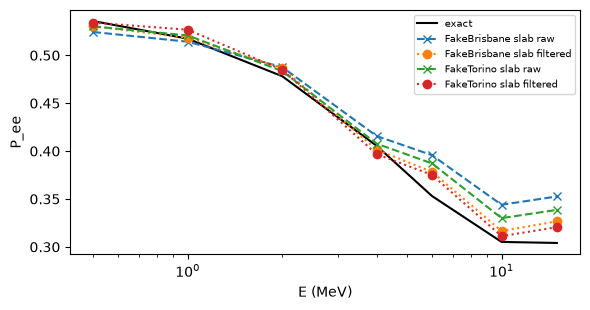

total time 255 s


In [7]:
H, X, RS = 100.0, 800.0, 8
E_SOL = (0.0005, 0.001, 0.002, 0.004, 0.006, 0.010, 0.015)   # GeV
pee = lambda p2s: np.array([nu.solar_pee_from_p2(float(p)) for p in p2s])
ex = pee([nu.solar_p2_exact(E, H, X) for E in E_SOL])
slab = pee([nu.solar_p2(E, H, X, RS) for E in E_SOL])
print("exact P_ee      ", np.round(ex, 3))
print("adiabatic P_ee  ", np.round([nu.solar_pee_adiabatic(E) for E in E_SOL], 3))
print(f"slab circuit r = {RS} (noiseless) ", np.round(slab, 3))
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.semilogx(np.array(E_SOL) * 1e3, ex, "k-", label="exact")
for name in BACKENDS:
    b = getattr(fp, name)()
    so = run([nu.solar_circuit(E, H, X, RS) for E in E_SOL], b, 1, 4000)
    co = run([nu.solar_circuit(E, H, X, RS, compiled=True) for E in E_SOL], b, 1, 4000)
    qo = run([nu.solar_circuit(E, H, X, RS, encoding="qubit") for E in E_SOL], b, None, 4000)
    est = {"slab raw": pee([ibm.occupations(o, "raw")[1] for o in so]),
           "slab filtered+readout": pee([ibm.occupations(o, FR)[1] for o in so]),
           "compiled raw": pee([ibm.occupations(o, "raw")[1] for o in co]),
           "compiled filtered+readout": pee([ibm.occupations(o, FR)[1] for o in co]),
           "one qubit readout": pee([ibm.occupations(o, "readout")[0] for o in qo])}
    print(name)
    for k, v in est.items():
        print(f"  {k:26s} mean |error| vs noiseless circuit {np.abs(v - slab).mean():.4f}   MSW drop {v[0] - v[5]:.3f}")
    ax.semilogx(np.array(E_SOL) * 1e3, est["slab raw"], "x--", label=f"{name} slab raw")
    ax.semilogx(np.array(E_SOL) * 1e3, est["slab filtered+readout"], "o:", label=f"{name} slab filtered")
ax.set_xlabel("E (MeV)"); ax.set_ylabel("P_ee"); ax.legend(fontsize=7); plt.tight_layout(); plt.show()
print(f"total time {time.time() - T0:.0f} s")

## Summary

* **Vacuum (§151):** the oscillation is a rotation; at the maximum the mixing angle is a quarter of the qang angle, with a θ-independent error bar. Three flavours fit the weight-1 sector and the filter cuts the error about 3×.
* **Matter (§152):** the Earth fakes a CP asymmetry larger than the CP signal itself; the filtered circuit recovers it.
* **Collective (§154):** the conserved number is the number of ν₂; the filter works on mass-basis read-outs, not on flavour ones.
* **Solar (§156):** the adiabatic MSW drop of P_ee is read with the filter, but because the phases are lost on the way, the observable is a population: the compiled one-rotation circuit beats any slab circuit, and one qubit is enough for two flavours.

Full details, pre-registered predictions and all backends: `RESEARCH_NOTES.md` §151–§156 and `examples/neutrino_*_qg.py`. §153 (Λ as a third filter in LiH) and §155 (the four quantum numbers) are not in a notebook yet.